In [13]:
import xarray as xr
import pandas as pd
import numpy as np
import os
import torch

# Create data directory if it doesn't exist
data_dir = 'WeatherData'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)

# Example: Downloading a subset of ERA5 data via CDS API
# Note: This requires a .cdsapirc file with your UID and API Key
# See: https://cds.climate.copernicus.eu/how-to-api

"""
import cdsapi

c = cdsapi.Client()

c.retrieve(
    'reanalysis-era5-single-levels',
    {
        'product_type': 'reanalysis',
        'format': 'netcdf',
        'variable': [
            '2m_temperature', 'total_precipitation',
        ],
        'year': '2023',
        'month': '01',
        'day': [
            '01', '02', '03',
        ],
        'time': [
            '00:00', '06:00', '12:00', '18:00',
        ],
    },
    os.path.join(data_dir, 'era5_sample.nc')
)
"""

# Since API keys are required for CDS, let's also provide a way to download 
# publicly available sample data from xarray's tutorial or NOAA OISST (Open Data)
print("Downloading sample high-dimensional weather data (NOAA OISST)...")

# NOAA Optimum Interpolated SST (Sea Surface Temperature) - Daily, 0.25 deg grid
# This is a good example of high-dimensional gridded time series
url = "https://www.ncei.noaa.gov/data/sea-surface-temperature-optimum-interpolation/v2.1/access/avhrr/202301/oisst-avhrr-v02r01.20230101.nc"
target_path = os.path.join(data_dir, 'oisst_sample.nc')

if not os.path.exists(target_path):
    import requests
    response = requests.get(url)
    with open(target_path, 'wb') as f:
        f.write(response.content)
    print(f"Downloaded: {target_path}")
else:
    print(f"File already exists: {target_path}")

# Load and inspect
ds = xr.open_dataset(target_path)
print("\nDataset Summary:")
print(ds)

# Show dimensions
print(f"\nDimensions: {dict(ds.dims)}")
print(f"Variables: {list(ds.data_vars)}")


File already exists: WeatherData/oisst_sample.nc

Dataset Summary:
<xarray.Dataset> Size: 17MB
Dimensions:  (time: 1, zlev: 1, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8B 2023-01-01T12:00:00
  * zlev     (zlev) float32 4B 0.0
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    sst      (time, zlev, lat, lon) float32 4MB ...
    anom     (time, zlev, lat, lon) float32 4MB ...
    err      (time, zlev, lat, lon) float32 4MB ...
    ice      (time, zlev, lat, lon) float32 4MB ...
Attributes: (12/37)
    Conventions:                CF-1.6, ACDD-1.3
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    references:                 Reynolds, et al.(2007) Daily High-Resolution-...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    id:                         oisst-avhrr-v02r01.2

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_56288/1524927704.py:65: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"\nDimensions: {dict(ds.dims)}")


In [14]:
# Extracting 2D array: (locations, time) for 100 time points
print("\nExtracting 2D array for 100 time points...")

# Note: The following code assumes 100 daily files have been downloaded to 'WeatherData/'
# oisst-avhrr-v02r01.20230101.nc to oisst-avhrr-v02r01.20230410.nc
files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.startswith('oisst-avhrr-v02r01') and f.endswith('.nc')])

if len(files) >= 100:
    # Open first 100 files
    ds_100 = xr.open_mfdataset(files[:100], combine='by_coords')
    
    # Extract Sea Surface Temperature (sst)
    # Dimensions are (time, zlev, lat, lon)
    # We squeeze to remove zlev (depth) which has size 1
    sst = ds_100.sst.squeeze()
    
    # Flatten spatial dimensions (lat, lon) into one 'location' dimension
    # Current shape: (100, 720, 1440)
    n_time, n_lat, n_lon = sst.shape
    
    # Each row should represent temperature at a specific location over time
    # Final shape: (n_locations, n_time)
    sst_2d = sst.values.reshape(n_time, -1).T
    
    print(f"Resulting 2D array shape: {sst_2d.shape}")
    print(f"Example data (first location, first 5 time points): {sst_2d[0, :5]}")
    
    # Save for later use
    np.save(os.path.join(data_dir, 'sst_2d_array.npy'), sst_2d)
else:
    print(f"Not enough files found in {data_dir}. Expected 100, found {len(files)}.")



Extracting 2D array for 100 time points...
Resulting 2D array shape: (1036800, 100)
Example data (first location, first 5 time points): [nan nan nan nan nan]


In [15]:
sst_2d.shape

(1036800, 100)

Filtering out land locations (NaNs) and low variance locations...
Total locations: 1036800
Valid sea locations: 691150
Locations after variance filtering (std > 0.01): 643646
Z-scoring the rows...
Applying DensMAP to 50000 locations...
Visualizing DensMAP projection...


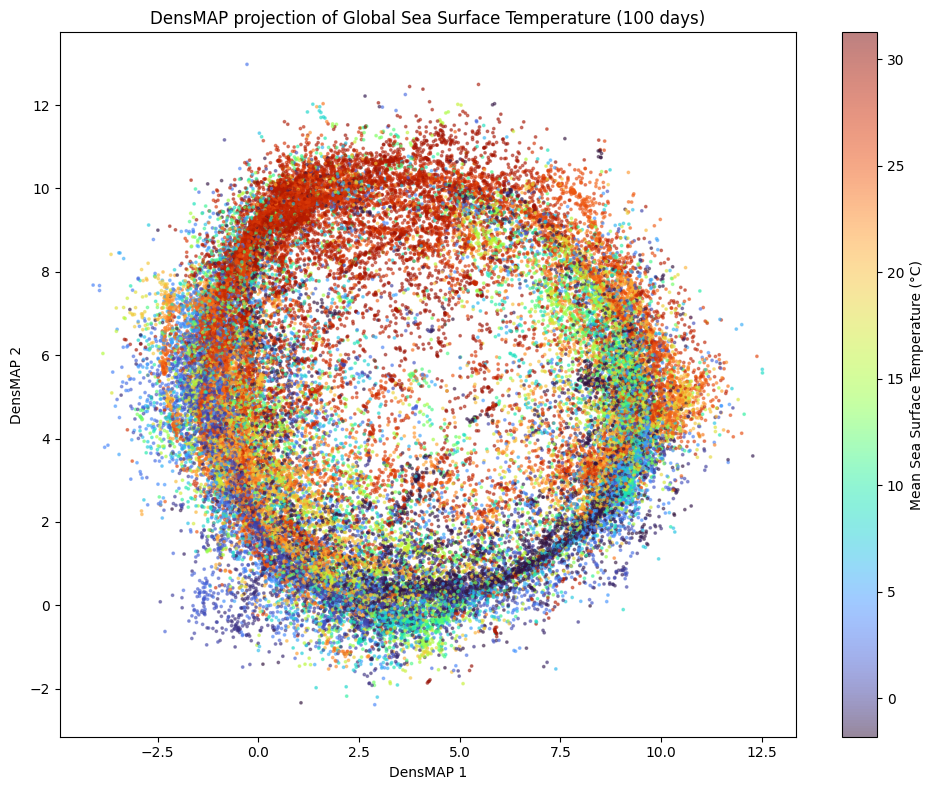

In [16]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Load data if not in memory
if 'sst_2d' not in locals():
    sst_2d = np.load(os.path.join(data_dir, 'sst_2d_array.npy'))

# 1. Filter out locations with NaNs (Land) and low variance
print("Filtering out land locations (NaNs) and low variance locations...")
mask_nan = ~np.isnan(sst_2d).any(axis=1)
sst_valid_temp = sst_2d[mask_nan]

# Calculate standard deviation for each valid location
sst_std_temp = np.std(sst_valid_temp, axis=1)

# Filter out locations with very little standard deviation (e.g., < 0.01)
std_threshold = 0.01
mask_std = sst_std_temp > std_threshold
sst_valid = sst_valid_temp[mask_std]

print(f"Total locations: {sst_2d.shape[0]}")
print(f"Valid sea locations: {sst_valid_temp.shape[0]}")
print(f"Locations after variance filtering (std > {std_threshold}): {sst_valid.shape[0]}")

# 2. Z-score the rows (normalize each location's time series)
print("Z-scoring the rows...")
sst_mean_all = np.mean(sst_valid, axis=1, keepdims=True)
sst_std_all = np.std(sst_valid, axis=1, keepdims=True) + 1e-8
sst_valid_norm = (sst_valid - sst_mean_all) / sst_std_all

# 3. Subsample for efficiency (DensMAP can be slow on 700k points)
# We'll take 50,000 points as a representative sample
n_sample = 50000
if sst_valid.shape[0] > n_sample:
    indices = np.random.choice(sst_valid.shape[0], n_sample, replace=False)
    sst_sample = sst_valid_norm[indices]
    mean_temp_sample = sst_mean_all[indices].flatten()
else:
    sst_sample = sst_valid_norm
    mean_temp_sample = sst_mean_all.flatten()

print(f"Applying DensMAP to {sst_sample.shape[0]} locations...")

# 3. Apply DensMAP
reducer = umap.UMAP(
    densmap=True, 
    dens_lambda=2,
    n_neighbors=100, 
)
embedding = reducer.fit_transform(sst_sample)

# 4. Visualize results
print("Visualizing DensMAP projection...")
plt.figure(figsize=(10, 8))

plt.scatter(
    embedding[:, 0], 
    embedding[:, 1], 
    c=mean_temp_sample, 
    cmap='turbo', 
    s=3, 
    alpha=0.5
)
plt.colorbar(label='Mean Sea Surface Temperature (°C)')
plt.title('DensMAP projection of Global Sea Surface Temperature (100 days)')
plt.xlabel('DensMAP 1')
plt.ylabel('DensMAP 2')
plt.tight_layout()

# Save figure
if not os.path.exists('../Figures'):
    os.makedirs('../Figures')
plt.savefig('../Figures/weather_densmap.png', dpi=300)
plt.show()


Computing mean speed of time series...
Creating side-by-side visualization...


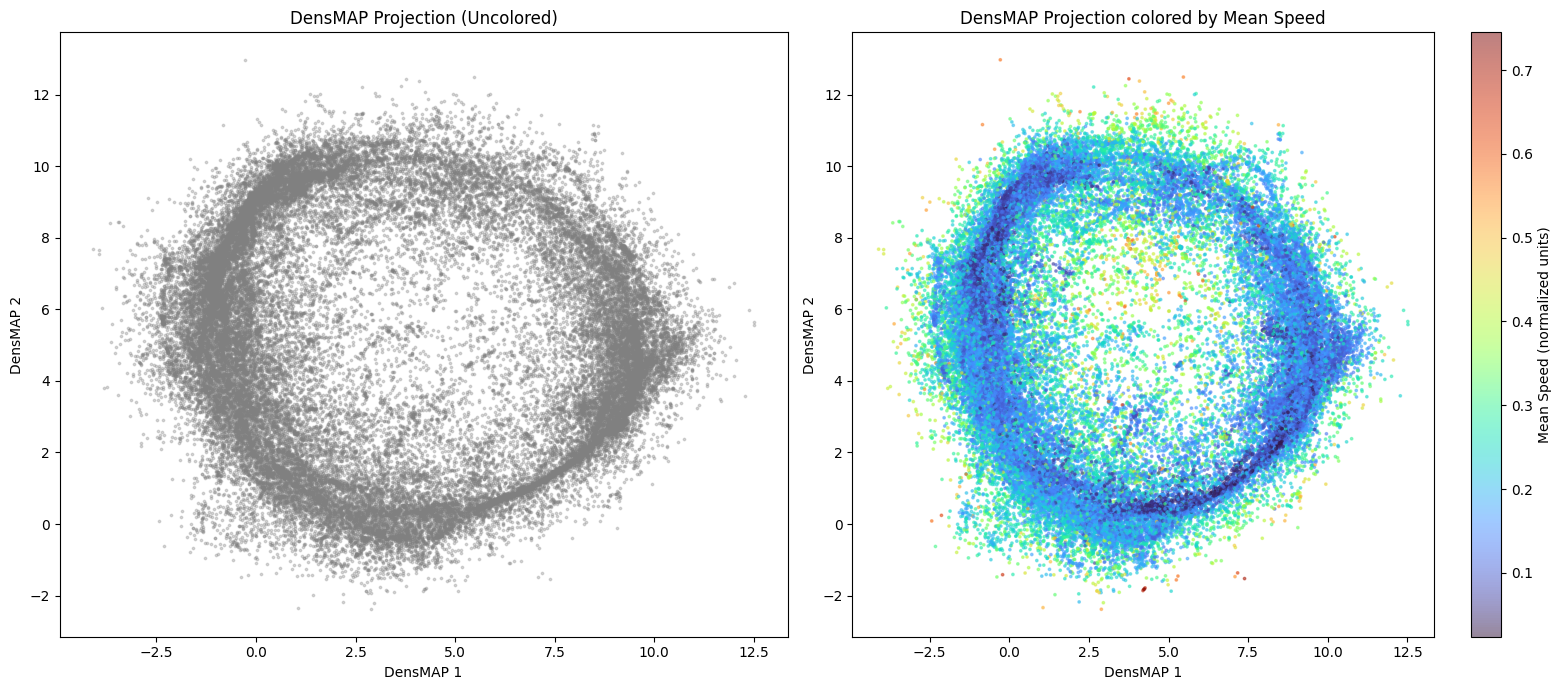

In [17]:
# 5. Compute mean speed and visualize
print("Computing mean speed of time series...")

# Speed = mean(abs(diff(sst_valid_norm)))
# Calculate for all valid locations first, then subsample using the same indices
sst_diff = np.diff(sst_valid_norm, axis=1)
speed_all = np.mean(np.abs(sst_diff), axis=1)
speed_sample = speed_all[indices]

print("Creating side-by-side visualization...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Left: Gray
ax1.scatter(
    embedding[:, 0], 
    embedding[:, 1], 
    color='gray', 
    s=3, 
    alpha=0.3
)
ax1.set_title('DensMAP Projection (Uncolored)')
ax1.set_xlabel('DensMAP 1')
ax1.set_ylabel('DensMAP 2')

# Right: Colored by Mean Speed
sc = ax2.scatter(
    embedding[:, 0], 
    embedding[:, 1], 
    c=speed_sample, 
    cmap='turbo', 
    s=3, 
    alpha=0.5
)
plt.colorbar(sc, ax=ax2, label='Mean Speed (normalized units)')
ax2.set_title('DensMAP Projection colored by Mean Speed')
ax2.set_xlabel('DensMAP 1')
ax2.set_ylabel('DensMAP 2')

plt.tight_layout()

# Save figure
plt.savefig('../Figures/weather_speed_manifold.png', dpi=300)
plt.show()


In [19]:
# 6. Rotation test for correlation between density and speed
from BWM.models.isometric_autoencoder import get_density_proxy
from scipy.stats import ortho_group, spearmanr
import torch

print("Computing manifold density and original correlation...")

# Use the same subsample (sst_sample) for density and speed
# sst_sample: (n_sample, 100)
# Convert to torch tensor for get_density_proxy
sst_sample_torch = torch.tensor(sst_sample, dtype=torch.float32)
density_sample = get_density_proxy(sst_sample_torch, k=50).numpy()

# Reference correlation (Speed vs Density)
# Note: get_density_proxy returns average k-NN distance, so higher value = lower density.
# We expect speed to be positively correlated with density, meaning negatively correlated with k-NN distance.
r_ref, _ = spearmanr(speed_sample, density_sample)
print(f"Reference Spearman Correlation (Speed vs k-NN Dist): {r_ref:.4f}")

# 7. Perform Rotation Test (1000 iterations)
n_rotations = 1000
print(f"Performing {n_rotations} random rotations of the high-dimensional data...")

coeffs = []
for i in range(n_rotations):
    # Generate random orthogonal matrix for the 100 time dimensions
    Q = ortho_group.rvs(sst_sample.shape[1])
    
    # Rotate the data
    sst_rotated = sst_sample @ Q
    
    # Recalculate speed (MSD) for rotated data
    speed_rot = np.mean(np.abs(np.diff(sst_rotated, axis=1)), axis=1)
    
    # Recalculate density for rotated data
    sst_rotated_torch = torch.tensor(sst_rotated, dtype=torch.float32)
    density_rot = get_density_proxy(sst_rotated_torch, k=50).numpy()
    
    # Compute correlation with recalculated density
    r_rot, _ = spearmanr(speed_rot, density_rot)
    coeffs.append(r_rot)
    
    if (i + 1) % 100 == 0:
        print(f"Completed {i + 1}/{n_rotations} rotations")

coeffs = np.array(coeffs)

# Calculate p-value (probability that rotated correlation is more extreme than reference)
# Since r_ref is negative (negative correlation with distance), 
# "higher correlation with density" means "more negative correlation with distance".
p_value = np.mean(coeffs < r_ref)
print(f"Probability (Rotated Corr < Reference Corr): {p_value:.4f}")

# 8. Visualize Null Distribution
plt.figure(figsize=(8, 5))
sns.histplot(coeffs, kde=True, color='gray', stat="probability")
plt.axvline(x=r_ref, color="#d9534f", linestyle="--", linewidth=2, 
            label=f"Reference Value ($r$ = {r_ref:.3f})")

plt.title(f"Null Distribution of Correlations (Random Rotations)\np-value: {p_value:.4f}")
plt.xlabel("Spearman Correlation (Speed vs k-NN distance)")
plt.ylabel("Probability")
plt.legend()
sns.despine()
plt.tight_layout()

# Save results
plt.savefig('../Figures/weather_rotation_test.png', dpi=300)
plt.show()


Computing manifold density and original correlation...
Reference Spearman Correlation (Speed vs k-NN Dist): 0.8219
Performing 1000 random rotations of the high-dimensional data...


KeyboardInterrupt: 


Performing Alternative Rotation Test (rotating the location dimension)...
Alternative Reference Spearman Correlation (Speed vs k-NN Dist): 0.7444
Performing 1000 random rotations of the location dimension (N=2000)...
Completed 100/1000 alternative rotations
Completed 200/1000 alternative rotations
Completed 300/1000 alternative rotations
Completed 400/1000 alternative rotations
Completed 500/1000 alternative rotations
Completed 600/1000 alternative rotations
Completed 700/1000 alternative rotations
Completed 800/1000 alternative rotations
Completed 900/1000 alternative rotations
Completed 1000/1000 alternative rotations
Alternative Probability (Rotated Corr < Reference Corr): 0.0000


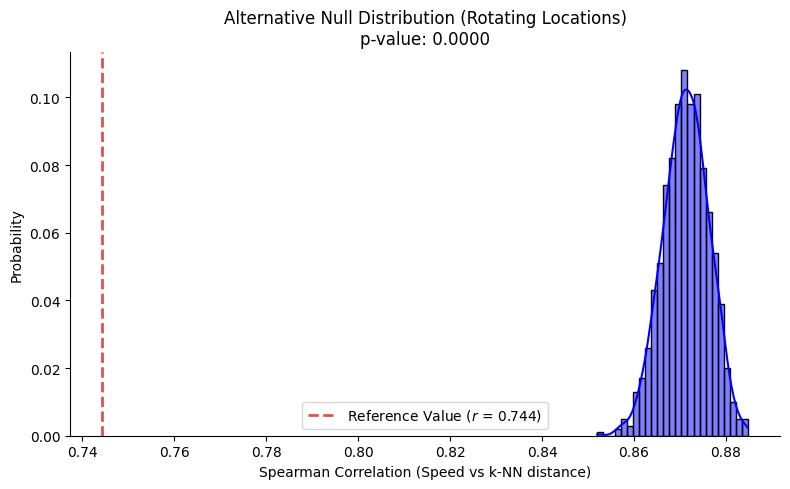

In [22]:
# 9. Alternative Rotation Test (Rotating the Location Dimension)
print("\nPerforming Alternative Rotation Test (rotating the location dimension)...")

# Use a smaller sample size to make rotating the location dimension feasible
n_sample_alt = 2000
if sst_valid.shape[0] > n_sample_alt:
    idx_alt = np.random.choice(sst_valid.shape[0], n_sample_alt, replace=False)
    sst_sample_alt = sst_valid_norm[idx_alt]
else:
    sst_sample_alt = sst_valid_norm
    n_sample_alt = sst_valid_norm.shape[0]

# Calculate speed and density for the alternative sample
speed_alt = np.mean(np.abs(np.diff(sst_sample_alt, axis=1)), axis=1)
sst_sample_alt_torch = torch.tensor(sst_sample_alt, dtype=torch.float32)
density_alt = get_density_proxy(sst_sample_alt_torch, k=50).numpy()

# Reference correlation for alternative sample
r_ref_alt, _ = spearmanr(speed_alt, density_alt)
print(f"Alternative Reference Spearman Correlation (Speed vs k-NN Dist): {r_ref_alt:.4f}")

n_rotations = 1000
coeffs_alt = []

print(f"Performing {n_rotations} random rotations of the location dimension (N={n_sample_alt})...")
for i in range(n_rotations):
    # Generate random orthogonal matrix for the location dimension
    Q = ortho_group.rvs(n_sample_alt)
    
    # Rotate the location dimension (Q @ sst_sample_alt)
    # This mixes the time series of different locations
    sst_rotated_alt = Q @ sst_sample_alt
    
    # Z-score the rows of the rotated matrix
    sst_rotated_alt = (sst_rotated_alt - np.mean(sst_rotated_alt, axis=1, keepdims=True)) / (np.std(sst_rotated_alt, axis=1, keepdims=True) + 1e-8)
    
    # Recalculate speed (MSD) for rotated data
    speed_rot_alt = np.mean(np.abs(np.diff(sst_rotated_alt, axis=1)), axis=1)
    
    # Recalculate density for rotated data
    sst_rotated_alt_torch = torch.tensor(sst_rotated_alt, dtype=torch.float32)
    density_rot_alt = get_density_proxy(sst_rotated_alt_torch, k=50).numpy()
    
    # Compute correlation with recalculated density
    r_rot_alt, _ = spearmanr(speed_rot_alt, density_rot_alt)
    coeffs_alt.append(r_rot_alt)
    
    if (i + 1) % 100 == 0:
        print(f"Completed {i + 1}/{n_rotations} alternative rotations")

coeffs_alt = np.array(coeffs_alt)
p_value_alt = np.mean(coeffs_alt < r_ref_alt)
print(f"Alternative Probability (Rotated Corr < Reference Corr): {p_value_alt:.4f}")

# Visualize Alternative Null Distribution
plt.figure(figsize=(8, 5))
sns.histplot(coeffs_alt, kde=True, color='blue', stat="probability")
plt.axvline(x=r_ref_alt, color="#d9534f", linestyle="--", linewidth=2, 
            label=f"Reference Value ($r$ = {r_ref_alt:.3f})")

plt.title(f"Alternative Null Distribution (Rotating Locations)\np-value: {p_value_alt:.4f}")
plt.xlabel("Spearman Correlation (Speed vs k-NN distance)")
plt.ylabel("Probability")
plt.legend()
sns.despine()
plt.tight_layout()

# Save alternative results
plt.savefig('../Figures/weather_rotation_test_alternative.png', dpi=300)
plt.show()
